## import

In [8]:
import requests, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import os
import json

from datetime import timedelta
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

## Downloading prices

Данные о временом ряде подружались с официального API московской биржи, ниже будет сравнение с данными из терминала т-банка, сходство вроде бы есть

Период который я выбрал для обучения модели с января 2024 года по настоящее время 

In [ ]:
session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=10, backoff_factor=1.5,
    status_forcelist=[500, 502, 503, 504],
    allowed_methods=["GET"],
    connect=10, read=10,
)))

def fetch_all_candles(ticker, interval=60, start="2024-07-01"):
    url = (f"https://iss.moex.com/iss/engines/stock/markets/shares/"
           f"boards/TQBR/securities/{ticker}/candles.json")
    rows_all, cols = [], None
    params = {"interval": interval, "from": start, "iss.meta": "off"}

    while True:
        # ретрай-цикл вокруг каждого запроса
        for attempt in range(6):
            try:
                r = session.get(url, params=params, timeout=30)
                r.raise_for_status()
                block = r.json()["candles"]
                break
            except Exception as e:
                print(f"  [попытка {attempt+1}] {type(e).__name__}: {e} — пауза")
                time.sleep(3 * (attempt + 1))
        else:
            print("  не удалось получить страницу, прерываю")
            break

        cols = block["columns"]
        rows = block["data"]
        if not rows:
            break

        rows_all.extend(rows)
        # пагинация по begin + 1 час — ISS это переваривает
        last_begin = pd.to_datetime(rows[-1][cols.index("begin")])
        params["from"] = (last_begin + timedelta(hours=1)).strftime("%Y-%m-%d %H:%M:%S")

        print(f"  {len(rows_all)} строк, далее from={params['from']}")
        if len(rows) < 500:
            break
        time.sleep(0.5)

    df = pd.DataFrame(rows_all, columns=cols)
    df["begin"] = pd.to_datetime(df["begin"])
    df["end"]   = pd.to_datetime(df["end"])
    return df.drop_duplicates(subset=["begin"]).reset_index(drop=True)


tickers = [
    "LKOH", # Лукойл
    "GAZP", # Гаспром
    "ROSN", # Роснефть
    "TRNFP", # Транснефть
    "SNGS", # Сургутнефтегаз
    "NVTK", # Новатэк
    "TATN", # Татнефть
]

for ticker in tickers:
    # Скачиваем
    df = fetch_all_candles(ticker, interval=60, start="2024-01-01")
    
    if not df.empty:
        # Сохраняем в отдельный CSV файл
        filename = f"data/{ticker}_1h.csv"
        df.to_csv(filename, index=False)
        print(f"Успешно сохранено: ({ticker}) -> {filename}, строк: {len(df)}")
    else:
        print(f"Не удалось загрузить данные для {ticker}")

  500 строк, далее from=2024-02-19 15:00:00
  1000 строк, далее from=2024-04-08 20:00:00
  1500 строк, далее from=2024-05-27 10:00:00
  2000 строк, далее from=2024-07-12 15:00:00
  2500 строк, далее from=2024-08-28 20:00:00
  3000 строк, далее from=2024-10-15 10:00:00
  3500 строк, далее from=2024-11-29 18:00:00
  4000 строк, далее from=2025-01-20 23:00:00
  4500 строк, далее from=2025-02-28 17:00:00
  5000 строк, далее from=2025-04-04 12:00:00
  5500 строк, далее from=2025-05-08 18:00:00
  6000 строк, далее from=2025-06-12 00:00:00
  6500 строк, далее from=2025-07-16 12:00:00
  7000 строк, далее from=2025-08-19 20:00:00
  7500 строк, далее from=2025-09-22 09:00:00
  8000 строк, далее from=2025-10-23 15:00:00
  8500 строк, далее from=2025-11-28 07:00:00
  9000 строк, далее from=2026-01-05 13:00:00
  9500 строк, далее from=2026-02-08 17:00:00
  10000 строк, далее from=2026-03-15 15:00:00
  10500 строк, далее from=2026-04-17 10:00:00
  11000 строк, далее from=2026-05-21 00:00:00
  11500 

In [54]:
df = pd.read_csv("data\LKOH_1h.csv", parse_dates=["begin", "end"])
df['begin'] = pd.to_datetime(df['begin'])
df['end'] = pd.to_datetime(df['end'])
df

<>:1: SyntaxWarning: invalid escape sequence '\L'
<>:1: SyntaxWarning: invalid escape sequence '\L'
C:\Users\redsk\AppData\Local\Temp\ipykernel_23412\4244243884.py:1: SyntaxWarning: invalid escape sequence '\L'
  df = pd.read_csv("data\LKOH_1h.csv", parse_dates=["begin", "end"])


,open,close,high,low,value,volume,begin,end
0,6774.0,6774.0,6774.0,6774.0,16108572.0,2378,2024-01-03 09:00:00,2024-01-03 09:59:59
1,6770.0,6762.5,6770.0,6745.5,202248679.5,29933,2024-01-03 10:00:00,2024-01-03 10:59:59
2,6761.0,6764.5,6770.0,6756.5,203736228.5,30119,2024-01-03 11:00:00,2024-01-03 11:59:59
3,6764.5,6770.0,6770.0,6757.0,140419665.0,20758,2024-01-03 12:00:00,2024-01-03 12:59:59
4,6770.0,6775.0,6776.5,6763.0,98782919.0,14588,2024-01-03 13:00:00,2024-01-03 13:59:59
...,...,...,...,...,...,...,...,...
13311,6122.0,6117.0,6122.0,6117.0,30245823.0,4943,2026-10-20 21:00:00,2026-10-20 21:59:59
13312,6117.0,6113.0,6125.0,6112.5,108792185.5,17786,2026-10-20 22:00:00,2026-10-20 22:59:59
13313,6112.5,6117.0,6118.0,6111.0,71018831.5,11615,2026-10-20 23:00:00,2026-10-20 23:59:57
13314,6130.0,6130.0,6130.0,6130.0,4744620.0,774,2026-10-21 06:00:00,2026-10-21 06:59:59


## Missing date

Так как в некоторые дни биржа закрыта я решил заранее обозначить их и вы

In [ ]:
existing_dates = pd.to_datetime(df["begin"]).dt.floor("D").unique()

start_date = pd.Timestamp("2024-01-01")
end_date = pd.Timestamp("2026-10-21")

full_calendar = pd.date_range(start=start_date, end=end_date, freq="D")

missing_dates = sorted(list(set(full_calendar.date) - set(existing_dates.date)))
missing_dates

[datetime.date(2024, 1, 1),
 datetime.date(2024, 1, 2),
 datetime.date(2024, 1, 6),
 datetime.date(2024, 1, 7),
 datetime.date(2024, 1, 13),
 datetime.date(2024, 1, 14),
 datetime.date(2024, 1, 20),
 datetime.date(2024, 1, 21),
 datetime.date(2024, 1, 27),
 datetime.date(2024, 1, 28),
 datetime.date(2024, 2, 3),
 datetime.date(2024, 2, 4),
 datetime.date(2024, 2, 10),
 datetime.date(2024, 2, 11),
 datetime.date(2024, 2, 17),
 datetime.date(2024, 2, 18),
 datetime.date(2024, 2, 23),
 datetime.date(2024, 2, 24),
 datetime.date(2024, 2, 25),
 datetime.date(2024, 3, 2),
 datetime.date(2024, 3, 3),
 datetime.date(2024, 3, 8),
 datetime.date(2024, 3, 9),
 datetime.date(2024, 3, 10),
 datetime.date(2024, 3, 16),
 datetime.date(2024, 3, 17),
 datetime.date(2024, 3, 23),
 datetime.date(2024, 3, 24),
 datetime.date(2024, 3, 30),
 datetime.date(2024, 3, 31),
 datetime.date(2024, 4, 6),
 datetime.date(2024, 4, 7),
 datetime.date(2024, 4, 13),
 datetime.date(2024, 4, 14),
 datetime.date(2024, 4, 20

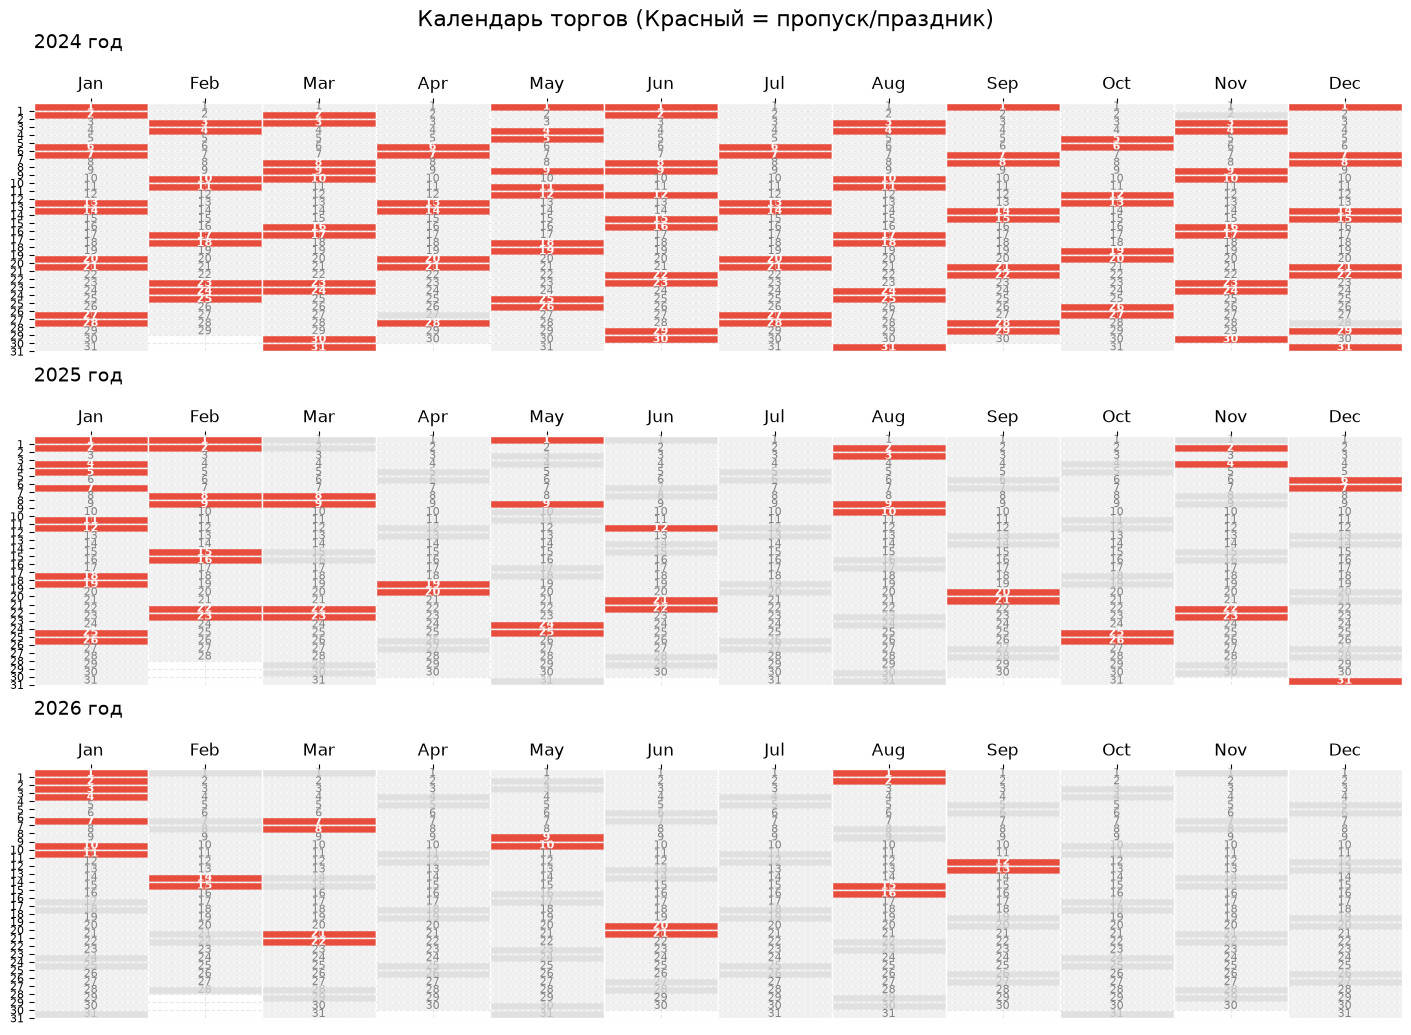

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
import calendar

missing_dates = pd.to_datetime(missing_dates)

years = [2024, 2025, 2026]
fig, axes = plt.subplots(len(years), 1, figsize=(14, 10), constrained_layout=True)
fig.suptitle('Календарь торгов (Красный = пропуск/праздник)', fontsize=16, y=1.02)

for idx, year in enumerate(years):
    ax = axes[idx]
    
    ax.set_xlim(0, 12)
    ax.set_ylim(31, 0) 

    ax.set_xticks(np.arange(12) + 0.5)
    ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)], fontsize=12)
    ax.xaxis.tick_top()
    
    ax.set_yticks(np.arange(1, 32))
    ax.set_yticklabels(np.arange(1, 32), fontsize=8)
    
    ax.grid(True, color='lightgray', linestyle='--', alpha=0.5)
    ax.set_title(f"{year} год", fontsize=14, pad=20, loc='left')

    for spine in ax.spines.values():
        spine.set_visible(False)

    for month in range(1, 13):
        days_in_month = calendar.monthrange(year, month)[1]
        
        for day in range(1, days_in_month + 1):
            current_date = pd.Timestamp(year=year, month=month, day=day)
            x = month - 1  
            y = day       

            if current_date in missing_dates:
                rect = Rectangle((x, y - 1), 1, 1, facecolor='#e74c3c', edgecolor='white')
                ax.add_patch(rect)
            
                ax.text(x + 0.5, y - 0.5, str(day), color='white', ha='center', va='center', fontsize=8, fontweight='bold')
            else:
                if current_date.weekday() < 5:
                    rect = Rectangle((x, y - 1), 1, 1, facecolor='#f0f0f0', edgecolor='white')
                    ax.add_patch(rect)
                    ax.text(x + 0.5, y - 0.5, str(day), color='gray', ha='center', va='center', fontsize=8)
                else: 
                    rect = Rectangle((x, y - 1), 1, 1, facecolor='#e0e0e0', edgecolor='white')
                    ax.add_patch(rect)
                    ax.text(x + 0.5, y - 0.5, str(day), color='silver', ha='center', va='center', fontsize=8)

plt.show()

Статическая версия временова ряда 

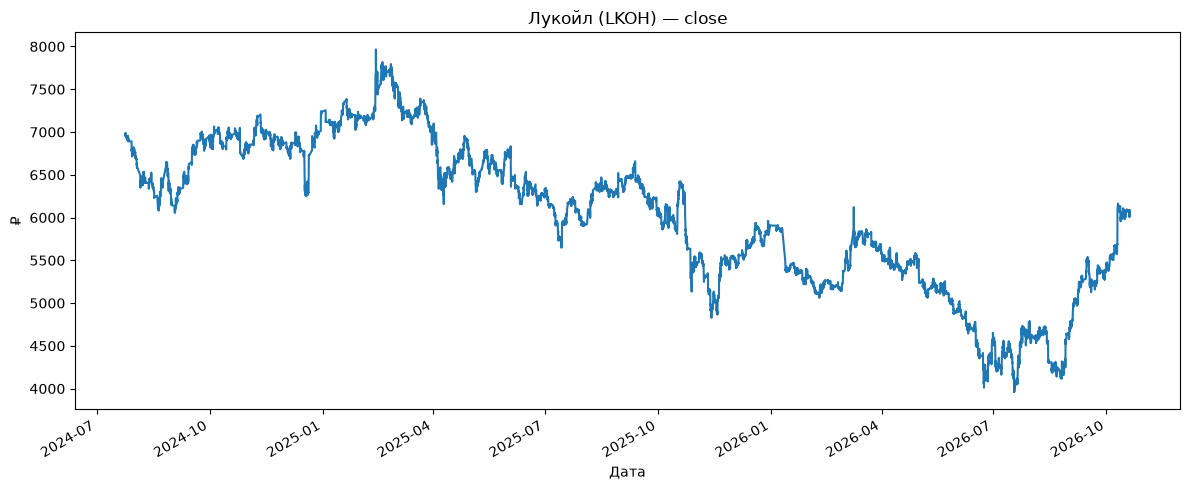

In [76]:
start = pd.Timestamp("2024-07-24")
end   = pd.Timestamp("2026-10-20")

mask = df["begin"].between(start, end)
sub  = df.loc[mask].set_index("begin")["close"]

ax = sub.plot(figsize=(12, 5), title="Лукойл (LKOH) — close", ylabel="₽")
ax.set_xlabel("Дата")
plt.tight_layout()
plt.show()

Динамическая. Судя по графику данные актуальны и сходство имеется

In [45]:
sub = df.loc[df["begin"].between("2026-10-07", "2026-10-08")]

fig = px.line(
    sub, x="begin", y="close", 
    title="Лукойл (LKOH) — Интерактивный график дня",
    labels={"begin": "Дата и время", "close": "Цена (₽)"},
    template="plotly_white"
)

fig.update_layout(
    height=600,
    hovermode="x unified",
    xaxis=dict(rangeslider=dict(visible=True), type="date")
)

fig.show()

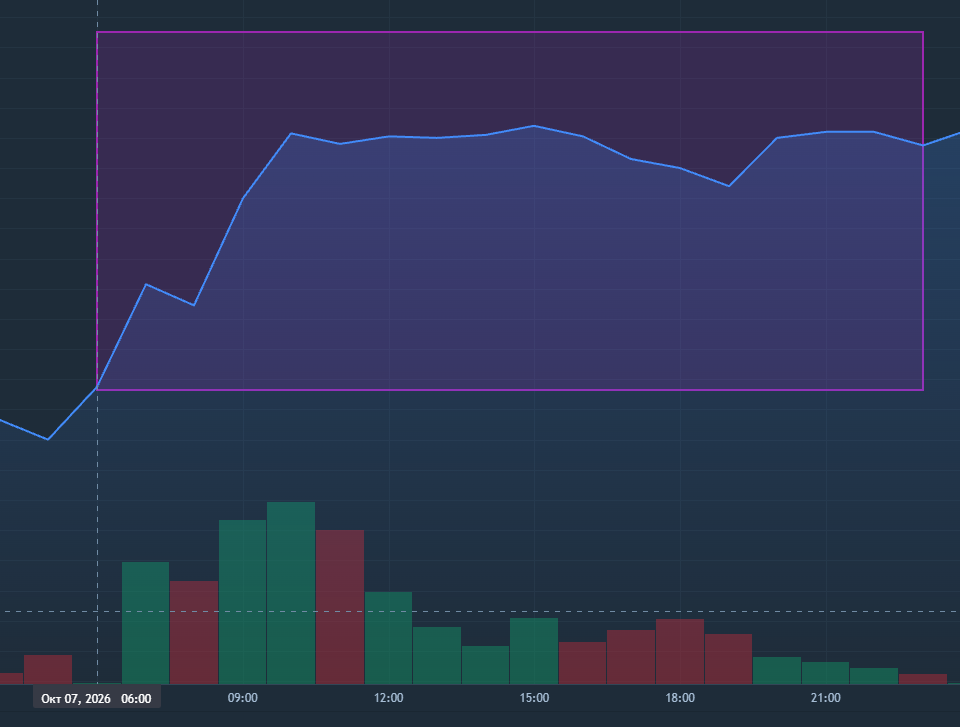

## Downloading news

Первый набор данных собран с помощью парсера который считывал данные с сайта https://www.kommersant.ru/archive/publishing/86/day за период с мая 2025 года по октябрь 2026. К сожалению из за логики сайта собрать новости за все часы времени не получилось и в данных присудствует существенный дисбаланс

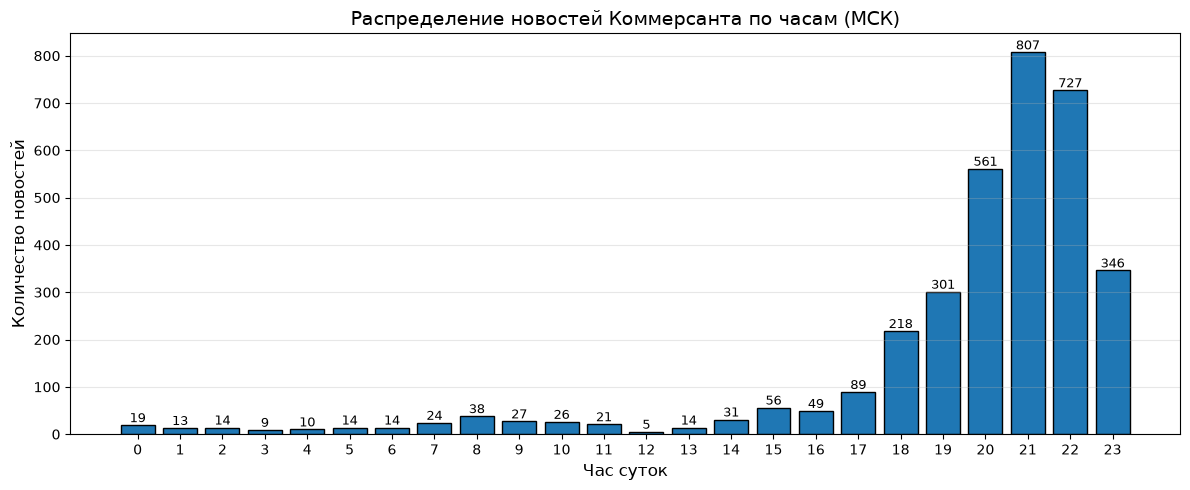

In [2]:
df = pd.read_csv("data/kommersant_news.csv")
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df_clean = df.dropna(subset=['date']).copy()

# 2. Переводим время в московское (UTC+3)
# Если в CSV время указано с "Z" (UTC), pandas уже знает, что это UTC.
df_clean['date_msk'] = df_clean['date'].dt.tz_convert('Europe/Moscow')

# 3. Вытаскиваем час из даты
df_clean['hour'] = df_clean['date_msk'].dt.hour

# 4. Строим график
plt.figure(figsize=(12, 5))
counts = df_clean['hour'].value_counts().sort_index()

# Рисуем столбцы (bar)
bars = plt.bar(counts.index, counts.values, color='#1f77b4', edgecolor='black')

# Настраиваем оси и подписи
plt.title('Распределение новостей Коммерсанта по часам (МСК)', fontsize=14)
plt.xlabel('Час суток', fontsize=12)
plt.ylabel('Количество новостей', fontsize=12)
plt.xticks(range(0, 24)) # Показываем все 24 часа
plt.grid(axis='y', alpha=0.3)

# Добавляем цифры над столбцами, чтобы было наглядно
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height,
                 f'{int(height)}',
                 ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [3]:
df

,url,date,title,text
0,https://www.kommersant.ru/doc/8634047,2026-05-01 18:32:04+00:00,Лавров и Аракчи обсудили пропуск российских су...,Министр иностранных дел России Сергей Лавров и...
1,https://www.kommersant.ru/doc/8634046,2026-05-01 18:15:01+00:00,США пригрозили санкциями за взносы Ирану для п...,США введут санкции в отношении грузоотправител...
2,https://www.kommersant.ru/doc/8634044,2026-05-01 17:41:14+00:00,Силы ПВО сбили 33 беспилотника ВСУ над Россией...,Средства ПВО уничтожили 33 беспилотника Вооруж...
3,https://www.kommersant.ru/doc/8634042,2026-05-01 17:28:08+00:00,Названа предварительная причина жесткой посадк...,Предварительная причина жесткой посадки вертол...
4,https://www.kommersant.ru/doc/8634041,2026-05-01 17:07:47+00:00,Трамп раскритиковал новое мирное предложение И...,"Президент США Дональд Трамп заявил, что недово..."
...,...,...,...,...
3430,https://www.kommersant.ru/doc/9044474,2026-10-22 05:43:37+00:00,ТАСС: попытка атаки БПЛА на Москву стала одной...,В ночь на 22 октября силы ПВО отразили одну из...
3431,https://www.kommersant.ru/doc/9044470,2026-10-22 05:36:36+00:00,В Воронежской области при атаке БПЛА поврежден...,Силы ПВО ночью сбили над Воронежской областью ...
3432,https://www.kommersant.ru/doc/9044469,2026-10-22 05:34:49+00:00,Армия России поразила предприятия ВПК в Киеве ...,Российские военнослужащие сегодня ночью нанесл...
3433,https://www.kommersant.ru/doc/9044457,2026-10-22 05:31:03+00:00,Частота покупок в магазинах дрогери снизилась ...,Как следует из данных аналитической компании I...


Второй ресурс это бесплатный API с новостями - https://freenewsapi.ai/ 

У данного сервиса есть лимит - можно собрать новости макисмум за последнии 30 дней. 

In [ ]:
queries = [
    "LKOH OR Лукойл", "GAZP OR Газпром", "ROSN OR Роснефть",
    "TRNFP OR Транснефть", "SNGS OR Сургутнефтегаз",
    "NVTK OR НОВАТЭК", "TATN OR Татнефть",
    "нефть OR нефтянка", "санкции нефть", "ОПЕК"
]

all_news = []
for q in queries:
    print(f"Ищем: {q}")
    r = requests.get(
        "https://freenewsapi.ai/v1/search",
        params={"q": q, "date": "30d", "size": 100, "full_text": True, "lang": "ru"},
        timeout=30
    )
    if r.status_code == 200:
        all_news.extend(r.json().get("results", []))
    time.sleep(1)

# Сохраняем
df = pd.DataFrame(all_news)
df.to_csv("data/geopolitics_news.csv", index=False)
print(f"Собрано {len(df)} новостей")

Ищем: LKOH OR Лукойл
Ищем: GAZP OR Газпром
Ищем: ROSN OR Роснефть
Ищем: TRNFP OR Транснефть
Ищем: SNGS OR Сургутнефтегаз
Ищем: NVTK OR НОВАТЭК
Ищем: TATN OR Татнефть
Ищем: нефть OR нефтянка
Ищем: санкции нефть
Ищем: ОПЕК
Собрано 200 новостей


In [31]:
df = pd.read_csv("data/geopolitics_news.csv")
df['published_at'] = pd.to_datetime(df['published_at'], errors='coerce')
df = df.drop(columns=['title', 'crawled_at','id','tld','image','author','lang','country_source'], errors='ignore')
df.to_csv("data/geopolitics_news.csv", index=False)
df

,url,description,published_at,host,sitename,country,categories,text
0,https://unn.ua/ru/news/dizelnaya-sdelka-trampa...,"Президент Чехии считает, что соглашение о пост...",2026-10-22 07:17:29+00:00,unn.ua,Украинские Национальные Новости (УНН),UA,['Война в Украине'],"""Дизельная"" сделка Трампа и путина сорвала мир..."
1,https://kiev-news.ru/society/2026/10/22/404057...,"Словакия возобновляет консультации с Россией, ...",2026-10-22 05:09:23+00:00,kiev-news.ru,Лента новостей Киева,RU,NaN,"Словакия возобновляет консультации с Россией, ..."
2,https://moskva-news.ru/tg/2026/10/22/103686.html,"Словакия возобновляет консультации с Россией, ...",2026-10-22 05:06:45+00:00,moskva-news.ru,Лента новостей Москвы,RU,NaN,"Словакия возобновляет консультации с Россией, ..."
3,https://vz.ru/news/2026/10/22/1466097.html,Стоимость декабрьских фьючерсов на нефть марки...,2026-10-22 01:52:09+00:00,vz.ru,Деловая газета Взгляд,RU,['Новости дня'],"Есть несколько тем, по которым Еврокомиссия и ..."
4,https://www.vedomosti.ru/business/news/2026/10...,Слова вице-премьера и министра финансов Сербии...,2026-10-21 18:11:26+00:00,www.vedomosti.ru,Ведомости,RU,"['Новости', 'Бизнес']",Эксперт допустил снятие Трампом санкций с росс...
...,...,...,...,...,...,...,...,...
195,https://delo.ua/ru/news/saudovskaya-araviya-uv...,"Саудовская Аравия сообщила ОПЕК, что ее добыча...",2026-10-13 14:17:24+00:00,delo.ua,Delo_Ua,UA,['Новости'],- Категория\n- Новости\n- Дата публикации\n- Д...
196,https://news-orenburg.ru/other/2026/10/13/3286...,Под председательством заместителя Председателя...,2026-10-13 13:19:39+00:00,news-orenburg.ru,Лента новостей Оренбурга,RU,NaN,Александр Новак провел ряд совещаний по ситуац...
197,https://www.kommersant.ru/doc/9025580,Организация стран-экспортеров нефти (ОПЕК) сни...,2026-10-13 12:50:47+00:00,www.kommersant.ru,Коммерсантъ,RU,NaN,ОПЕК снизила оценку роста спроса на нефть до 1...
198,https://1prime.ru/20261013/rossija-874191423.html,Россия и Центральная Азия в августе текущего г...,2026-10-13 12:18:00+00:00,1prime.ru,ПРАЙМ,RU,['Новости'],https://1prime.ru/20261013/rossija-874191423.h...


## Marking news

В связи с небольшим сроком для выполнения работы было приняти решение использовать для разметки данных API LLM. 

Мой выбор пал на сайт https://apinex.bond/ 

Сервис предостовляет щедрые ограничение, а также можно пользоваться любимым китайским другом DeepSeek 4 версии бесплатной 

In [ ]:
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
DATA_DIR = os.path.join(BASE_DIR, "data")

INPUT_FILE = os.path.join(DATA_DIR, "kommersant_news.csv") 

OUTPUT_CSV = os.path.join(DATA_DIR, "labeled_geopolitics.csv")
OUTPUT_JSONL = os.path.join(DATA_DIR, "labeled_geopolitics.jsonl")

os.makedirs(DATA_DIR, exist_ok=True)

API_KEY = "Ну типо токен"

SYSTEM = """Ты — финансовый аналитик нефтегазового сектора РФ. Твоя задача — разметить новость.
Отвечай СТРОГО в формате JSON со следующими ключами:
{
  "REL": "ДА" или "НЕТ", 
  "TYPE": "Авария" | "Санкции" | "Финансы" | "Сделки" | "Законы" | "Цены" | "Другое",
  "DIR": "Позитив" | "Негатив" | "Нейтрально",
  "MAG": "Высокий" | "Средний" | "Низкий",
  "FREQ": "Разовое" | "Периодическое" | "Постоянное"
}

ПРАВИЛА:
1. REL: "ДА", если новость касается нефти, газа, энергетики РФ, санкций против них, либо ГЛОБАЛЬНОЙ ГЕОПОЛИТИКИ, влияющей на цены/поставки (например, Ормузский пролив, ОПЕК, конфликты на Ближнем Востоке). "НЕТ" — если это вообще не про энергетику (спорт, культура, внутренняя политика без связи с нефтью).
2. TYPE: выбери ровно одно значение из списка.
3. DIR: как это повлияет на акции нефтянки РФ. (Блокада пролива = Позитив для цен на нефть, но Негатив для стабильности).
4. MAG: 
   - "Высокий": прямые удары по НПЗ, крупные санкции, блокировка проливов, резкие скачки цен (>3%).
   - "Средний": локальные события, риски, аналитика.
   - "Низкий": слухи, "может быть", малозначимые события.
5. FREQ: как часто такое бывает.
6. НИКАКОГО текста вне JSON, никакого Markdown.
"""

def label_news(text):
    if not text or not isinstance(text, str) or not text.strip():
        return None
    
    text = text[:2500] 
    
    while True:
        try:
            r = requests.post(
                "https://api.apinex.bond/v1/chat/completions",
                headers={"Authorization": f"Bearer {API_KEY}"},
                json={
                    "model": "free/deepseek-v4-pro-0813",
                    "messages": [
                        {"role": "system", "content": SYSTEM},
                        {"role": "user", "content": text},
                    ],
                    "temperature": 0.0,
                    "response_format": {"type": "json_object"},
                },
                timeout=30,
            )
            
            if r.status_code == 429:
                print("  ! Достигнут лимит (429). Ждем 60 секунд...")
                time.sleep(60)
                continue
                
            r.raise_for_status()
            
            raw_content = r.json()["choices"][0]["message"]["content"]
            parsed_data = json.loads(raw_content)
            return parsed_data
            
        except requests.exceptions.RequestException as e:
            print(f"  ! Ошибка сети: {e}. Ждем 10 секунд...")
            time.sleep(10)
        except Exception as e:
            print(f"  ! Ошибка API: {e}")
            return None

if not os.path.exists(INPUT_FILE):
    print(f"Файл {INPUT_FILE} не найден! Убедитесь, что он лежит в папке data.")
    exit()

df = pd.read_csv(INPUT_FILE)
print(f"Загружено {len(df)} новостей из {INPUT_FILE}")

processed_urls = set()
if os.path.exists(OUTPUT_CSV):
    try:
        existing_df = pd.read_csv(OUTPUT_CSV)
        processed_urls = set(existing_df["url"])
        print(f"Найдено {len(processed_urls)} уже размеченных новостей. Пропускаем их.")
    except Exception:
        pass

for idx, row in df.iterrows():
    url = row.get("url", "Нет URL")
    
    if url in processed_urls:
        continue
        
    text = row.get("text", "") 
    if pd.isna(text) or not text:
        text = row.get("title", "")
        
    if pd.isna(text) or not text:
        print(f"[{idx+1}/{len(df)}] Пропуск: пустой текст.")
        continue

    print(f"[{idx+1}/{len(df)}] Размечаем: {str(row.get('title', ''))[:60]}...")
    
    label = label_news(str(text))
    
    if label:
        label["url"] = url
        label["published_at"] = row.get("date", "")
        label["title"] = row.get("title", "")
        
        with open(OUTPUT_JSONL, "a", encoding="utf-8") as f:
            f.write(json.dumps(label, ensure_ascii=False) + "\n")
            
        df_one = pd.DataFrame([label])
        header = not os.path.exists(OUTPUT_CSV)
        df_one.to_csv(OUTPUT_CSV, mode='a', header=header, index=False, encoding='utf-8')
        
        print(f"  + REL={label.get('REL')} | TYPE={label.get('TYPE')} | DIR={label.get('DIR')} | MAG={label.get('MAG')}")
    else:
        print("  - Не удалось разметить.")
        
    time.sleep(10) 

print(f"\nГотово! Результаты сохранены в: {OUTPUT_CSV}")

## Feature engineering

Далее была написана функция для высчитывания дополнительных признаков. 

Их можно разделить на 5 групп: 
- Технические
- Временные
- Новостные метрики
- Трендовые метрики
- Метрики пробоя и отскока

А также метрика целевого класса (поднялась цена по сравнению с прошлым часом или опустилась на определённый процент)

Подробнее написанно в отчёте

In [12]:
def build_features(prices_df, news_df):
    df = prices_df.copy()
    df['begin'] = pd.to_datetime(df['begin'])
    
    # --- 1. Технические (Базовые) ---
    df['log_ret'] = np.log(df['close'] / df['close'].shift(1))
    df['prev_close'] = df['close'].shift(1)
    df['tr'] = np.maximum(df['high'] - df['low'], 
                          np.maximum(abs(df['high'] - df['prev_close']), abs(df['low'] - df['prev_close'])))
    df['atr_14'] = df['tr'].rolling(14).mean()
    
    for w in [5, 10, 20, 50]:
        df[f'sma_{w}'] = df['close'].rolling(w).mean()
        df[f'ema_{w}'] = df['close'].ewm(span=w, adjust=False).mean()
        
    # ВОТ ЭТИХ ДВУХ СТРОК НЕ ХВАТАЛО:
    df['ema_12'] = df['close'].ewm(span=12, adjust=False).mean()
    df['ema_26'] = df['close'].ewm(span=26, adjust=False).mean()

    df['macd'] = df['ema_12'] - df['ema_26']
    df['macd_signal'] = df['macd'].ewm(span=9, adjust=False).mean()
    df['macd_hist'] = df['macd'] - df['macd_signal']
    
    delta = df['close'].diff()
    gain = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean()
    df['rsi_14'] = 100 - 100 / (1 + gain / loss)
    
    df['bb_mid'] = df['sma_20']
    df['bb_std'] = df['close'].rolling(20).std()
    df['bb_upper'] = df['bb_mid'] + 2 * df['bb_std']
    df['bb_lower'] = df['bb_mid'] - 2 * df['bb_std']
    df['bb_width'] = (df['bb_upper'] - df['bb_lower']) / df['bb_mid']
    df['bb_pos'] = (df['close'] - df['bb_lower']) / (df['bb_upper'] - df['bb_lower'])
    
    typ_price = (df['high'] + df['low'] + df['close']) / 3
    df['date'] = df['begin'].dt.date
    df['vwap'] = (typ_price * df['volume']).groupby(df['date']).cumsum() / df['volume'].groupby(df['date']).cumsum()
    
    # --- 2. Временные ---
    df['hour'] = df['begin'].dt.hour
    df['day_of_week'] = df['begin'].dt.dayofweek
    df['is_first_hour'] = (df['hour'] == 10).astype(int)
    df['is_last_hour'] = (df['hour'] == 18).astype(int)
    
    df['hours_since_last_trade'] = np.where(df['is_first_hour'] == 1, 
                                           (df['begin'] - df['begin'].shift(1)).dt.total_seconds() / 3600, 1)
    df['session_progress'] = (df['hour'] - 10) / 9
    
    # --- 4. Трендовые ---
    df['ma_slope'] = (df['sma_20'] - df['sma_20'].shift(3)) / df['sma_20'].shift(3)
    df['price_vs_ma50'] = (df['close'] - df['sma_50']) / df['sma_50']
    df['ma_alignment'] = ((df['sma_10'] > df['sma_20']) & (df['sma_20'] > df['sma_50'])).astype(int)
    
    df['up_move'] = df['high'].diff()
    df['down_move'] = -df['low'].diff()
    df['plus_dm'] = np.where((df['up_move'] > df['down_move']) & (df['up_move'] > 0), df['up_move'], 0)
    df['minus_dm'] = np.where((df['down_move'] > df['up_move']) & (df['down_move'] > 0), df['down_move'], 0)
    df['atr_sum'] = df['tr'].rolling(14).sum()
    df['di_plus'] = 100 * (df['plus_dm'].rolling(14).sum() / df['atr_sum'])
    df['di_minus'] = 100 * (df['minus_dm'].rolling(14).sum() / df['atr_sum'])
    df['dx'] = 100 * abs(df['di_plus'] - df['di_minus']) / (df['di_plus'] + df['di_minus'])
    df['adx_14'] = df['dx'].ewm(alpha=1/14, adjust=False).mean()
    
    # --- 5. Пробой / Отскок ---
    df['max_high_20'] = df['high'].rolling(20).max()
    df['min_low_20'] = df['low'].rolling(20).min()
    df['pos_in_range'] = (df['close'] - df['min_low_20']) / (df['max_high_20'] - df['min_low_20'])
    df['dist_to_resistance'] = (df['max_high_20'] - df['close']) / df['atr_14']
    df['dist_to_support'] = (df['close'] - df['min_low_20']) / df['atr_14']
    df['bb_squeeze'] = df['bb_width'] / df['bb_width'].rolling(20).mean()
    df['vol_sma_20'] = df['volume'].rolling(20).mean()
    df['volume_ratio'] = df['volume'] / df['vol_sma_20']
    df['is_breakout_high'] = (df['close'] > df['max_high_20'].shift(1)).astype(int)
    df['rsi_oversold_bounce'] = ((df['rsi_14'] < 30) & (df['close'] > df['open'])).astype(int)
    df['rsi_overbought_drop'] = ((df['rsi_14'] > 70) & (df['close'] < df['open'])).astype(int)
    
    # --- 3. Новостные (NLP) ---
    if not news_df.empty:
        news_df = news_df.copy()
        news_df['published_at'] = pd.to_datetime(news_df['published_at'], errors='coerce').dt.tz_localize(None)
        news_df = news_df.dropna(subset=['published_at'])  # Убираем новости без даты
        news_df['hour'] = news_df['published_at'].dt.floor('h')
        
        sentiment_map = {'Позитив': 1, 'Негатив': -1, 'Нейтрально': 0}
        news_df['sentiment'] = news_df['DIR'].map(sentiment_map)
        
        hourly = news_df.groupby('hour').agg(
            sentiment_mean=('sentiment', 'mean'),
            sentiment_min=('sentiment', 'min'),
            news_count=('sentiment', 'count'),
            event_catastrophe_flag=('TYPE', lambda x: int((x == 'Авария').any())),
            uncertainty_score=('title', lambda x: sum(('возможно' in str(t).lower()) or ('может' in str(t).lower()) for t in x) / len(x) if len(x) > 0 else 0)
        ).reset_index().rename(columns={'hour': 'begin'})
        
        df = pd.merge(df, hourly, on='begin', how='left')
    else:
        df[['sentiment_mean', 'sentiment_min', 'news_count', 'event_catastrophe_flag', 'uncertainty_score']] = 0
    
    df[['sentiment_mean', 'sentiment_min', 'news_count', 'event_catastrophe_flag', 'uncertainty_score']] = df[['sentiment_mean', 'sentiment_min', 'news_count', 'event_catastrophe_flag', 'uncertainty_score']].fillna(0)
    
    df['sentiment_delta_1h'] = df['sentiment_mean'] - df['sentiment_mean'].rolling(1).mean().shift(1)
    df['sentiment_delta_4h'] = df['sentiment_mean'] - df['sentiment_mean'].rolling(4).mean().shift(1)
    df['sentiment_delta_24h'] = df['sentiment_mean'] - df['sentiment_mean'].rolling(24).mean().shift(1)
    
    # --- Таргеты ---
    df['future_close_3h'] = df['close'].shift(-3)
    df['ratio_3h'] = df['future_close_3h'] / df['close']
    df['target_binary'] = (df['ratio_3h'] > 1.005).astype(int)
    df['target_multiclass'] = np.where(df['ratio_3h'] > 1.005, 2, 
                                       np.where(df['ratio_3h'] < 0.995, 0, 1))
    
    # --- Очистка ---
    drop_cols = ['prev_close', 'date', 'tr', 'up_move', 'down_move', 
                 'plus_dm', 'minus_dm', 'atr_sum', 'dx', 'future_close_3h', 'ratio_3h',
                 'ema_12', 'ema_26'] # <--- Добавил ema_12 и ema_26 в удаляемые, чтобы не засорять датасет
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    df = df.dropna().reset_index(drop=True)
    
    return df

In [13]:
from tqdm import tqdm  

prices = pd.read_csv("data/stocks/LKOH_1h.csv")
news = pd.read_csv("data/labeled_geopolitics.csv") 

with tqdm(total=1, desc="Генерация метрик") as pbar:
    df_final = build_features(prices, news)
    pbar.update(1)

df_final.to_csv("data/stocks/LKOH_features.csv", index=False)

Генерация метрик: 100%|██████████| 1/1 [00:00<00:00,  2.69it/s]


In [15]:
df_final

,open,close,high,low,value,volume,begin,end,log_ret,atr_14,...,sentiment_mean,sentiment_min,news_count,event_catastrophe_flag,uncertainty_score,sentiment_delta_1h,sentiment_delta_4h,sentiment_delta_24h,target_binary,target_multiclass
0,6802.0,6797.0,6802.0,6793.0,88102075.0,12961,2024-01-08 13:00:00,2024-01-08 13:59:59,-0.000735,8.392857,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0,1
1,6797.0,6793.0,6799.5,6781.0,102973545.0,15164,2024-01-08 14:00:00,2024-01-08 14:59:59,-0.000589,9.464286,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0,1
2,6792.5,6788.5,6795.0,6782.5,56197186.0,8278,2024-01-08 15:00:00,2024-01-08 15:59:59,-0.000663,10.142857,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0,1
3,6788.5,6784.5,6790.0,6780.5,66774953.0,9842,2024-01-08 16:00:00,2024-01-08 16:59:59,-0.000589,10.500000,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0,1
4,6783.5,6768.0,6784.5,6756.0,276791151.5,40890,2024-01-08 17:00:00,2024-01-08 17:59:59,-0.002435,12.107143,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13262,6122.0,6117.0,6122.0,6117.0,30245823.0,4943,2026-10-20 21:00:00,2026-10-20 21:59:59,-0.000899,33.500000,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.282143,0.067857,0,1
13263,6117.0,6113.0,6125.0,6112.5,108792185.5,17786,2026-10-20 22:00:00,2026-10-20 22:59:59,-0.000654,33.357143,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.232143,0.067857,0,1
13264,6112.5,6117.0,6118.0,6111.0,71018831.5,11615,2026-10-20 23:00:00,2026-10-20 23:59:57,0.000654,32.392857,...,0.000000,0.0,0.0,0.0,0.0,0.000000,0.107143,0.067857,0,1
13265,6130.0,6130.0,6130.0,6130.0,4744620.0,774,2026-10-21 06:00:00,2026-10-21 06:59:59,0.002123,27.214286,...,-0.333333,-1.0,6.0,1.0,0.0,-0.333333,-0.333333,-0.265476,0,1


In [17]:
df_final['target_multiclass'].value_counts()

target_multiclass
1    9450
0    1962
2    1855
Name: count, dtype: int64